# Validación con tráfico de 2025

**Trabajo final · Aprendizaje Automático I** — Celia Sáenz Villalta

Este cuaderno complementa a `trabajo_bots_vs_humanos.ipynb`. Allí se desarrolla el método con el log de 2019 y se entrena el modelo, que se guarda en `modelos/modelo_2019.pkl`. Aquí se comprueba si ese modelo **generaliza a tráfico actual**: se aplica a un log de 2025, se reentrena con esos datos y se valida con las reglas de ataque que acompañan al dataset.

| | |
|---|---|
| Fuente | *Web Server Log Dataset* (2026), Zenodo, registro 20001206 |
| Contenido | Log Apache de un organismo público de Indonesia («Organización X») |
| Tamaño | 213 205 peticiones, 23/09/2025 – 07/10/2025 (15 ficheros de rotación diaria) |
| Licencia | MIT |
| Etiquetas | Reglas de *ground truth* de ataques (`ground-truth/organization-x.yaml`) |

Las IPs vienen anonimizadas de origen. El tráfico es muy distinto al de 2019: monitorización, escáneres de vulnerabilidades y algún *crawler* de IA.

In [1]:
import re, gzip, zipfile, io, glob, os, hashlib, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

warnings.filterwarnings('ignore', category=UserWarning)
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 80)
sns.set_theme(style='whitegrid')

SEMILLA = 0
N_INIT = 50
RUTA_2025 = 'datos/organization-x/log/apache2/web-access.log*'    # varios ficheros, algunos .gz
os.makedirs('figuras', exist_ok=True)
if not os.path.isdir('datos/organization-x'):
    zipfile.ZipFile('datos/organization-x.zip').extractall('datos')

with open('modelos/modelo_2019.pkl', 'rb') as f:
    modelo19 = pickle.load(f)
VARIABLES = modelo19['variables']
print(f"Modelo de 2019 cargado: k = {modelo19['k']}, variables = {VARIABLES}")

Modelo de 2019 cargado: k = 7, variables = ['n_peticiones', 'media_dt', 'cv_dt', 'pct_estaticos', 'pct_4xx', 'pidio_robots', 'pct_sin_referer', 'pct_head', 'pct_urls_distintas']


Las funciones de carga, construcción de sesiones, etiquetado y clasificación son las mismas que en el cuaderno principal; se copian aquí para que este cuaderno pueda ejecutarse de forma independiente.

In [2]:
PATRON_COMBINED = re.compile(
    r'^(?P<ip>\S+) \S+ \S+ \[(?P<fecha>[^\]]+)\] '
    r'"(?P<metodo>[A-Z]+) (?P<url>\S+)(?: \S+)?" '
    r'(?P<codigo>\d{3}) (?P<tamano>\d+|-) '
    r'"(?P<referer>[^"]*)" "(?P<user_agent>[^"]*)"'
)

def _abrir(ruta):
    """Abre un log en modo texto, tanto si es plano como si está comprimido (.gz o .zip)."""
    if ruta.endswith('.gz'):
        return gzip.open(ruta, 'rt', encoding='utf-8', errors='replace')
    if ruta.endswith('.zip'):
        z = zipfile.ZipFile(ruta)
        miembro = max(z.infolist(), key=lambda i: i.file_size)   # el log es el fichero más grande
        return io.TextIOWrapper(z.open(miembro), encoding='utf-8', errors='replace')
    return open(ruta, encoding='utf-8', errors='replace')

def anonimizar(ip):
    return hashlib.md5(ip.encode()).hexdigest()[:10]

FORMATO_FECHA = '%d/%b/%Y:%H:%M:%S %z'

def cargar_log(ruta, n_lineas=None, horas=None, anonimizar_ip=True, verbose=True):
    """Lee un log en formato combined y devuelve un DataFrame con una petición por fila.

    n_lineas: máximo de líneas a leer. horas: lee solo las primeras `horas` horas desde la primera petición.
    """
    rutas = sorted(glob.glob(ruta)) if isinstance(ruta, str) else list(ruta)
    filas, leidas, malas, limite, parar = [], 0, 0, None, False
    for r in rutas:
        with _abrir(r) as f:
            for linea in f:
                if n_lineas is not None and leidas >= n_lineas:
                    break
                leidas += 1
                m = PATRON_COMBINED.match(linea)
                if not m:
                    malas += 1
                    continue
                filas.append(m.groupdict())
                if horas is not None and (limite is None or len(filas) % 10_000 == 0):
                    try:
                        t = pd.to_datetime(filas[-1]['fecha'], format=FORMATO_FECHA)
                    except ValueError:
                        continue
                    if limite is None:
                        limite = t + pd.Timedelta(hours=horas)
                    elif t > limite:          # se comprueba cada 10 000 líneas; luego se recorta exacto
                        parar = True
                        break
        if parar:
            break
    df = pd.DataFrame(filas)
    df['fecha'] = pd.to_datetime(df['fecha'], format=FORMATO_FECHA, errors='coerce')
    malas += df['fecha'].isna().sum()
    df = df.dropna(subset=['fecha'])
    if limite is not None:
        df = df[df['fecha'] < limite]
    df['codigo'] = df['codigo'].astype(int)
    df['tamano'] = pd.to_numeric(df['tamano'], errors='coerce').fillna(0).astype(int)
    if anonimizar_ip:
        df['ip'] = df['ip'].map(anonimizar)
    if verbose:
        print(f'{len(rutas)} fichero(s), {leidas:,} líneas leídas, {malas:,} descartadas '
              f'({malas / max(leidas, 1):.4%})')
    return df.reset_index(drop=True)

EXT_ESTATICOS = re.compile(
    r'(?:\.(?:css|js|png|jpe?g|gif|svg|ico|webp|woff2?|ttf|eot|map|mp4|webm)(?:\?|$))'
    r'|^/(?:images?|static|styles?|scripts|js|css|plugins|fonts|assets)/', re.I)

CANDIDATAS = ['n_peticiones', 'duracion_s', 'pet_por_min', 'media_dt', 'cv_dt', 'pct_estaticos',
              'pct_4xx', 'pidio_robots', 'pct_sin_referer', 'pct_head', 'pct_urls_distintas']

VARIABLES_LOG = ['n_peticiones', 'duracion_s', 'pet_por_min', 'media_dt', 'cv_dt']

def crear_sesiones(df, inactividad_min=30):
    """Asigna a cada petición un identificador de sesión (misma IP y user-agent, corte por inactividad)."""
    df = df.sort_values(['ip', 'user_agent', 'fecha']).reset_index(drop=True)
    cambio = (df['ip'] != df['ip'].shift()) | (df['user_agent'] != df['user_agent'].shift())
    hueco = df['fecha'].diff().dt.total_seconds()
    nueva = cambio | (hueco > inactividad_min * 60)
    df['sesion'] = nueva.cumsum()
    df['dt'] = hueco.where(~nueva)        # segundos desde la petición anterior de la misma sesión
    return df

def calcular_variables(df):
    """Una fila por sesión con las variables de comportamiento."""
    d = df.assign(estatico=df['url'].str.contains(EXT_ESTATICOS),
                  error4xx=df['codigo'].between(400, 499),
                  robots=df['url'].str.contains(r'robots\.txt|sitemap', case=False),
                  sin_referer=df['referer'].isin(['-', '']),
                  head=df['metodo'].eq('HEAD'))
    g = d.groupby('sesion')
    ses = pd.DataFrame({
        'ip': g['ip'].first(),
        'user_agent': g['user_agent'].first(),
        'inicio': g['fecha'].min(),
        'n_peticiones': g.size(),
        'duracion_s': (g['fecha'].max() - g['fecha'].min()).dt.total_seconds(),
        'media_dt': g['dt'].mean(),
        'std_dt': g['dt'].std(ddof=0),
        'pct_estaticos': g['estatico'].mean(),
        'pct_4xx': g['error4xx'].mean(),
        'pidio_robots': g['robots'].max().astype(int),
        'pct_sin_referer': g['sin_referer'].mean(),
        'pct_head': g['head'].mean(),
        'pct_urls_distintas': g['url'].nunique() / g.size(),
    })
    ses['pet_por_min'] = ses['n_peticiones'] / np.maximum(ses['duracion_s'], 1) * 60
    ses['cv_dt'] = (ses['std_dt'] / ses['media_dt'].replace(0, np.nan)).fillna(0)
    return ses

CRAWLERS_IA = re.compile(
    r'GPTBot|ChatGPT-User|OAI-SearchBot|ClaudeBot|Claude-User|Claude-SearchBot|anthropic-ai|'
    r'PerplexityBot|Perplexity-User|Bytespider|Amazonbot|CCBot|meta-externalagent|Google-Extended|'
    r'Applebot-Extended|cohere-ai|Diffbot|YouBot|DuckAssistBot|MistralAI', re.I)

BOTS = re.compile(
    r'bot|crawl|spider|slurp|uptime|monitor|curl|python|wget|scan|go-http|java/|libwww|okhttp|'
    r'axios|node-fetch|headless|phantom|httpclient|facebookexternalhit|zgrab|masscan|nmap|nikto|'
    r'sqlmap|feed|fetch|preview|^-?$', re.I)

def etiqueta_ua(ua):
    if CRAWLERS_IA.search(ua):
        return 'crawler_IA'
    if BOTS.search(ua):
        return 'bot_declarado'
    return 'navegador'

MOVIL = re.compile(r'Android|iPhone|iPad|iPod|\biOS\b|Mobile|Dalvik|CFNetwork|NetworkingExtension|'
                   r'Windows Phone|BlackBerry|Opera Mini|webOS|KaiOS|SamsungBrowser', re.I)

def es_movil(ses):
    """Sesiones de navegador con user-agent móvil (los bots declarados nunca se marcan)."""
    return ses['user_agent'].str.contains(MOVIL) & ses['tipo_ua'].eq('navegador')

def tipo_cliente(ua):
    if etiqueta_ua(ua) != 'navegador':
        return 'bot declarado'
    return 'móvil' if MOVIL.search(ua) else 'ordenador'

def matriz(ses, variables=None):
    """Matriz de variables transformadas con log(1+x) cuando procede (sin estandarizar)."""
    variables = VARIABLES if variables is None else variables
    X = ses[variables].copy()
    logv = [v for v in variables if v in VARIABLES_LOG]
    X[logv] = np.log1p(X[logv])
    return X

def evaluar_kmeans(Z, ks, muestra):
    filas = []
    for k in ks:
        km = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEMILLA).fit(Z)
        filas.append({'k': k, 'inercia': km.inertia_,
                      'silhouette': silhouette_score(Z[muestra], km.labels_[muestra]),
                      'calinski_harabasz': calinski_harabasz_score(Z, km.labels_),
                      'davies_bouldin': davies_bouldin_score(Z, km.labels_)})
    return pd.DataFrame(filas).set_index('k')

def dibujar_metricas(met, titulo, fichero=None):
    fig, ax = plt.subplots(1, 4, figsize=(16, 3.2))
    for a, col in zip(ax, met.columns):
        a.plot(met.index, met[col], 'o-'); a.set_title(col); a.set_xlabel('k')
    fig.suptitle(titulo); plt.tight_layout()
    if fichero: plt.savefig(fichero, dpi=150)
    plt.show()

def perfil(datos, etiquetas):
    return datos[VARIABLES].groupby(etiquetas).median().assign(
        sesiones=pd.Series(etiquetas).value_counts().sort_index().values,
        peticiones=datos.groupby(etiquetas)['n_peticiones'].sum().values)

def nombrar(p):
    """Nombre y tipo de un clúster a partir de las medianas de su perfil."""
    if p['pct_head'] > 0.5:          return 'monitorización (HEAD)', 'automatizado'
    if p['pidio_robots'] > 0.5:      return 'crawler (pide robots.txt)', 'automatizado'
    if p['pct_4xx'] > 0.5:           return 'errores 4xx / sondeo', 'automatizado'
    if p['media_dt'] > 300 and p['pct_sin_referer'] >= 0.5:
        return 'crawler lento y regular', 'automatizado'
    if p['pct_sin_referer'] < 0.5:
        return ('navegación humana' if p['n_peticiones'] >= 10 else 'visita corta'), 'humano'
    if p['pct_estaticos'] >= 0.5:    return 'recursos sueltos sin referer', 'ambiguo'
    return 'acceso directo sin referer ni estáticos', 'ambiguo'

def nombrar_clusters(datos, etiquetas):
    p = perfil(datos, etiquetas)
    nombres = {c: nombrar(fila) for c, fila in p.iterrows()}
    return p.assign(nombre=[nombres[c][0] for c in p.index], tipo=[nombres[c][1] for c in p.index]), nombres

def mapa_perfil(Z, etiquetas, p, titulo, fichero=None):
    medias_z = pd.DataFrame(Z, columns=VARIABLES).groupby(etiquetas).mean()
    filas = [f'{c}: {p.loc[c, "nombre"]} (n={p.loc[c, "sesiones"]:,})' for c in medias_z.index]
    fig, ax = plt.subplots(figsize=(14, 0.6 * len(filas) + 1.5))
    sns.heatmap(medias_z.clip(-2.5, 2.5), annot=p[VARIABLES].round(2).values, fmt='', cmap='RdBu_r',
                center=0, yticklabels=filas, ax=ax, cbar_kws={'label': 'media estandarizada'})
    ax.set_title(titulo); plt.tight_layout()
    if fichero: plt.savefig(fichero, dpi=150)
    plt.show()

CATEGORIAS = ['humano', 'ambiguo', 'bot camuflado', 'bot declarado', 'crawler IA', '1 petición (sin clasificar)']

COLORES = dict(zip(CATEGORIAS, ['#4C72B0', '#A0A0A0', '#C44E52', '#DD8452', '#8172B3', '#D9D9D9']))

def entrenar_modelo(ses, k):
    """Entrena k-means sobre las sesiones (ya filtradas) con ≥ 2 peticiones y nombra los clústeres."""
    datos = ses[ses['n_peticiones'] > 1]
    esc = StandardScaler().fit(matriz(datos))
    km = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEMILLA).fit(esc.transform(matriz(datos)))
    _, nombres = nombrar_clusters(datos, km.labels_)
    return {'escalador': esc, 'kmeans': km, 'nombres': nombres}

def clasificar_sesiones(ses, modelo, solo_escritorio=True):
    ses = ses.copy()
    ses['tipo_ua'] = ses['user_agent'].map(etiqueta_ua)
    if solo_escritorio:
        movil = es_movil(ses)
        print(f'Sesiones móviles excluidas: {movil.sum():,} ({movil.mean():.1%})')
        ses = ses[~movil].copy()
    validas = ses['n_peticiones'] > 1
    ses['cluster'] = -1
    ses.loc[validas, 'cluster'] = modelo['kmeans'].predict(modelo['escalador'].transform(matriz(ses[validas])))
    ses['grupo'] = ses['cluster'].map(lambda c: modelo['nombres'].get(c, ('—', '—'))[0])
    tipo = ses['cluster'].map(lambda c: modelo['nombres'].get(c, ('—', '—'))[1])
    ses['categoria'] = np.select(
        [ses['tipo_ua'] == 'crawler_IA', ses['tipo_ua'] == 'bot_declarado', ~validas,
         tipo == 'automatizado', tipo == 'humano'],
        ['crawler IA', 'bot declarado', '1 petición (sin clasificar)', 'bot camuflado', 'humano'],
        default='ambiguo')
    return ses

def analizar_log(ruta, modelo, n_lineas=None, horas=None, titulo=None, dibujar=True, devolver_sesiones=False):
    """Estima qué parte del tráfico de un log es humana y qué parte automatizada."""
    log = crear_sesiones(cargar_log(ruta, n_lineas=n_lineas, horas=horas))
    ses = clasificar_sesiones(calcular_variables(log), modelo)
    res = pd.DataFrame({
        'sesiones': ses['categoria'].value_counts(),
        'peticiones': ses.groupby('categoria')['n_peticiones'].sum()}).reindex(CATEGORIAS).fillna(0).astype(int)
    res['% sesiones'] = (100 * res['sesiones'] / res['sesiones'].sum()).round(1)
    res['% peticiones'] = (100 * res['peticiones'] / res['peticiones'].sum()).round(1)
    if dibujar:
        fig, ax = plt.subplots(figsize=(10, 2.6))
        izq = np.zeros(2)
        for cat in CATEGORIAS:
            v = res.loc[cat, ['% sesiones', '% peticiones']].values.astype(float)
            ax.barh(['sesiones', 'peticiones'], v, left=izq, color=COLORES[cat], label=cat)
            for i, x in enumerate(v):
                if x >= 4: ax.text(izq[i] + x / 2, i, f'{x:.0f}%', ha='center', va='center', fontsize=9)
            izq += v
        ax.set(xlim=(0, 100), xlabel='%', title=titulo or ruta)
        ax.legend(ncol=3, fontsize=8, bbox_to_anchor=(0.5, -0.35), loc='upper center')
        plt.tight_layout()
        if titulo: plt.savefig(f'figuras/analizar_{re.sub(r"\W+", "_", titulo)}.png', dpi=150, bbox_inches='tight')
        plt.show()
    return (res, ses) if devolver_sesiones else res

## 1. Log de 2025 con el modelo entrenado en 2019

15 fichero(s), 213,205 líneas leídas, 5 descartadas (0.0023%)


Sesiones móviles excluidas: 1,788 (24.5%)


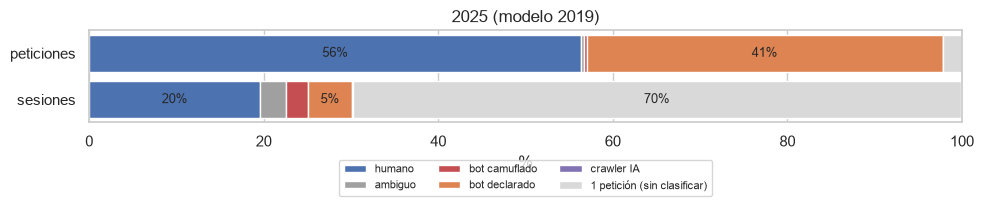

,sesiones,peticiones,% sesiones,% peticiones
categoria,,,,
humano,1081,100444,19.6,56.4
ambiguo,164,571,3.0,0.3
bot camuflado,140,623,2.5,0.3
bot declarado,275,72624,5.0,40.8
crawler IA,5,5,0.1,0.0
1 petición (sin clasificar),3837,3837,69.7,2.2


tipo_ua,bot_declarado,navegador,All
grupo,,,
acceso directo sin referer ni estáticos,11,164,175
crawler (pide robots.txt),0,1,1
crawler lento y regular,118,137,255
monitorización (HEAD),3,2,5
navegación humana,0,427,427
visita corta,116,654,770
All,248,1385,1633


In [3]:
res25_m19, ses25_m19 = analizar_log(RUTA_2025, modelo19, titulo='2025 (modelo 2019)', devolver_sesiones=True)
display(res25_m19)
v = ses25_m19[ses25_m19['cluster'] >= 0]
pd.crosstab(v['grupo'], v['tipo_ua'], margins=True)

In [4]:
v[VARIABLES].groupby(v['grupo']).median().round(2)

,n_peticiones,media_dt,cv_dt,pct_estaticos,pct_4xx,pidio_robots,pct_sin_referer,pct_head,pct_urls_distintas
grupo,,,,,,,,,
acceso directo sin referer ni estáticos,3.0,1.00,0.00,0.00,0.8,0.0,1.00,0.0,1.00
crawler (pide robots.txt),20.0,0.11,2.92,0.00,0.0,1.0,1.00,0.0,0.10
crawler lento y regular,3.0,0.50,1.00,0.00,0.0,0.0,1.00,0.0,1.00
monitorización (HEAD),4.0,0.33,1.41,0.00,0.0,0.0,1.00,1.0,0.50
navegación humana,33.0,1.87,3.47,0.73,0.0,0.0,0.14,0.0,0.94
visita corta,11.0,7.00,1.88,0.06,0.0,0.0,0.36,0.0,0.67


**// Comentario:** Al aplicar el modelo de 2019 al log de 2025 los centroides dejan de describir a las sesiones que se les asignan. El caso más claro es el del crawler lento: recibe 255 sesiones de 2025 cuya mediana de tiempo entre peticiones es de 0,5 s, cuando en 2019 este grupo se definía precisamente por pedir una página cada 722 s. Del mismo modo, las 770 sesiones asignadas a la «visita corta», entre ellas 116 bots declarados, apenas cargan recursos estáticos (mediana del 6 % frente al 100 % en 2019), y el grupo de acceso directo recibe sesiones con un 80 % de errores 4xx que, por las reglas de nombrado, deberían considerarse sondeos. **El modelo no generaliza directamente a una web de otra época y otra tecnología**, lo que justifica reentrenarlo con los datos de 2025.

## 2. Reentrenamiento con los datos de 2025

Dado que el tráfico de 2025 es muy distinto (otro tipo de web, otra época, mucho tráfico de escáneres), se repite el proceso de selección de k y se entrena un modelo propio con las sesiones de 2025. Los grupos se nombran con las mismas reglas que en 2019.

15 fichero(s), 213,205 líneas leídas, 5 descartadas (0.0023%)


Sesiones de ordenador en 2025: 5,502; con ≥ 2 peticiones: 1,633


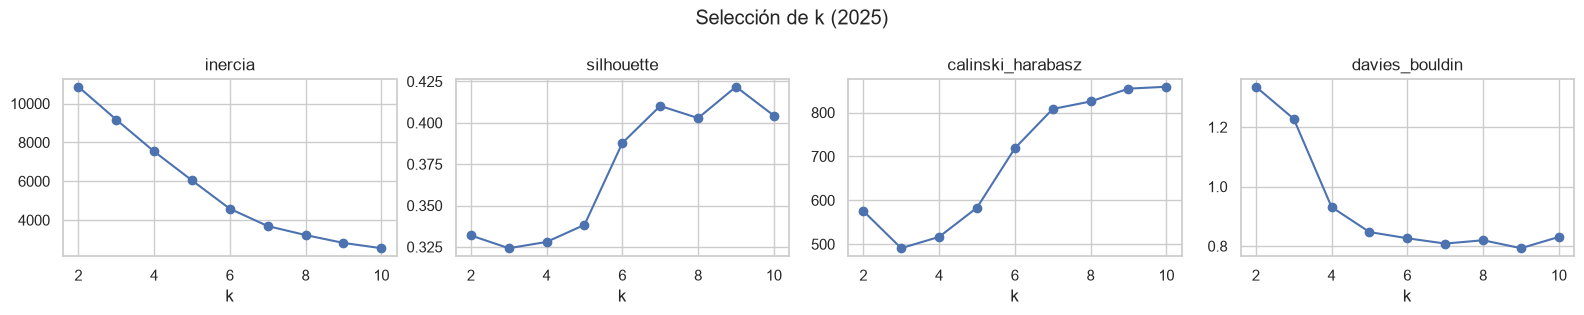

,inercia,silhouette,calinski_harabasz,davies_bouldin
k,,,,
2,10863.987,0.332,575.447,1.336
3,9172.863,0.324,490.814,1.228
4,7531.835,0.328,516.565,0.931
5,6041.334,0.338,583.129,0.847
6,4581.393,0.388,718.476,0.826
7,3691.214,0.410,808.018,0.808
8,3227.053,0.403,825.108,0.820
9,2821.567,0.422,854.388,0.793
10,2550.795,0.404,858.703,0.831


In [5]:
log25 = crear_sesiones(cargar_log(RUTA_2025))
ses25 = calcular_variables(log25)
ses25['tipo_ua'] = ses25['user_agent'].map(etiqueta_ua)
ses25 = ses25[~es_movil(ses25)].copy()
datos25 = ses25[ses25['n_peticiones'] > 1].copy()
print(f'Sesiones de ordenador en 2025: {len(ses25):,}; con ≥ 2 peticiones: {len(datos25):,}')
Z25 = StandardScaler().fit_transform(matriz(datos25))
met25 = evaluar_kmeans(Z25, range(2, 11), np.arange(len(Z25)))
dibujar_metricas(met25, 'Selección de k (2025)', 'figuras/seleccion_k_2025.png')
met25.round(3)

k elegido para 2025 (máximo silhouette): 9


15 fichero(s), 213,205 líneas leídas, 5 descartadas (0.0023%)


Sesiones móviles excluidas: 1,788 (24.5%)


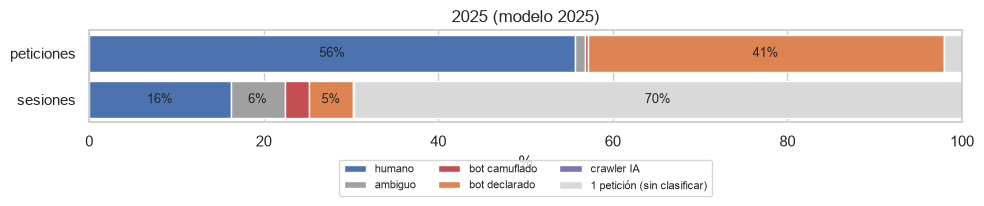

,sesiones,peticiones,% sesiones,% peticiones
categoria,,,,
humano,890,99131,16.2,55.7
ambiguo,343,1983,6.2,1.1
bot camuflado,152,524,2.8,0.3
bot declarado,275,72624,5.0,40.8
crawler IA,5,5,0.1,0.0
1 petición (sin clasificar),3837,3837,69.7,2.2


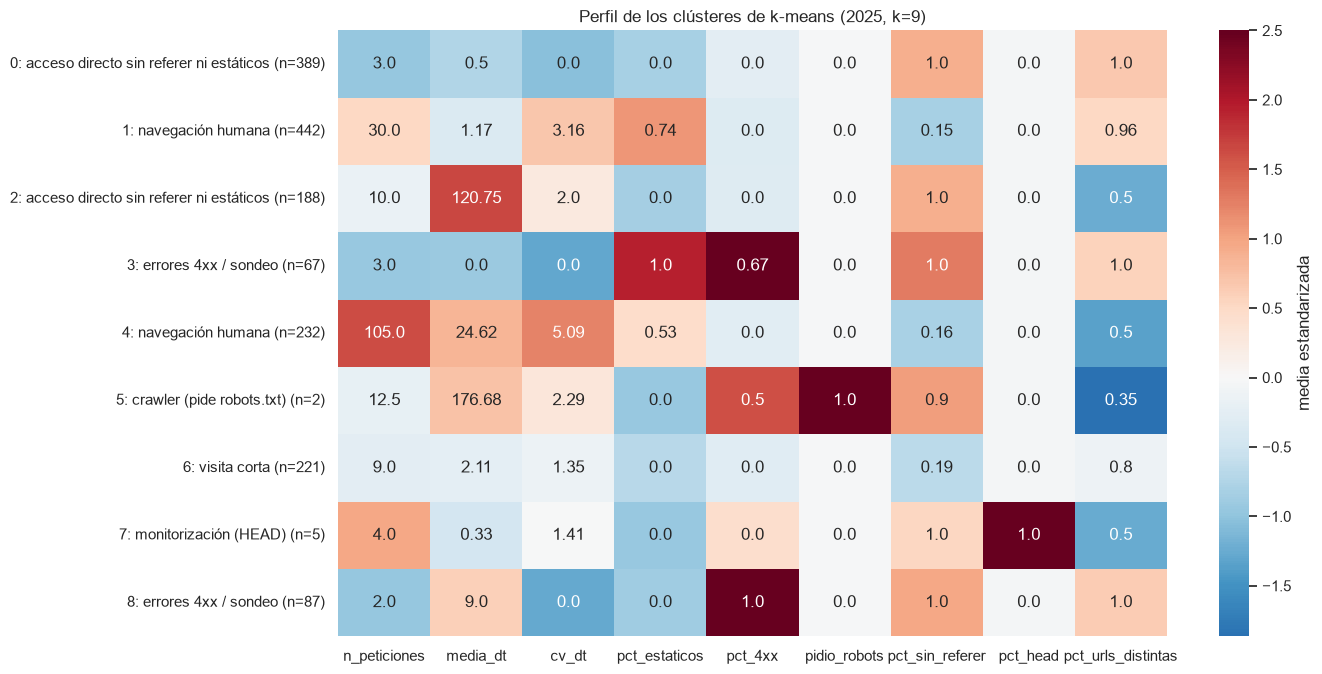

tipo_ua,bot_declarado,navegador,All
grupo,,,
acceso directo sin referer ni estáticos,234,343,577
crawler (pide robots.txt),0,2,2
errores 4xx / sondeo,6,148,154
monitorización (HEAD),3,2,5
navegación humana,3,671,674
visita corta,2,219,221
All,248,1385,1633


In [6]:
K25 = int(met25['silhouette'].idxmax())
print('k elegido para 2025 (máximo silhouette):', K25)
modelo25 = entrenar_modelo(ses25, K25)
res25_m25, ses25_m25 = analizar_log(RUTA_2025, modelo25, titulo='2025 (modelo 2025)', devolver_sesiones=True)
display(res25_m25)

v25 = ses25_m25[ses25_m25['cluster'] >= 0]
perfil25, _ = nombrar_clusters(v25, v25['cluster'].values)
Zv25 = modelo25['escalador'].transform(matriz(v25))
mapa_perfil(Zv25, v25['cluster'].values, perfil25, f'Perfil de los clústeres de k-means (2025, k={K25})',
            'figuras/perfil_clusters_2025.png')
pd.crosstab(v25['grupo'], v25['tipo_ua'], margins=True)

In [7]:
# ¿Qué piden las sesiones con user-agent de navegador del grupo de errores 4xx en 2025?
ids = v25.index[(v25['grupo'] == 'errores 4xx / sondeo') & (v25['tipo_ua'] == 'navegador')]
errores = log25[log25['sesion'].isin(ids) & log25['codigo'].between(400, 499)]
display(errores['url'].str[:60].value_counts().head(10).to_frame('peticiones 4xx'))
v25.loc[ids, 'user_agent'].str[:70].value_counts().head(6).to_frame('sesiones')

,peticiones 4xx
url,
/4.png,76
/5.png,76
/wp-admin/54.php,24
/wp-content/plugins/quiz-master-next/README.md,4
/wp-content/plugins/wp-file-manager/lib/php/connector.minima,3
/wp-content/plugins/delightful-downloads/assets/vendor/jquer,3
/wp-content/plugins/wsecure/244.php,3
/graphql,3
/wp-content/plugins/wp-payeezy-pay/260.php,3


,sesiones
user_agent,
Mozilla/5.0 (Windows NT 10.0; Win64; x64),25
com.apple.WebKit.Networking/20621.164.248.10.110 Network/4277.140.33 m,22
Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/605.1.15 (,17
"Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, l",11
com.apple.WebKit.Networking/21622.142.150.99.179 Network/5569.1.3 macO,8
com.apple.WebKit.Networking/20621.142.52.206.231 Network/4277.101.3 ma,5


**// Comentario:** En 2025 solo 1 633 de las 5 502 sesiones de ordenador tienen al menos dos peticiones, por lo que la muestra es mucho menor que la de 2019. En este caso la elección de k no plantea dudas: **k = 9** obtiene a la vez el mejor silhouette (0,422) y el mejor Davies-Bouldin (0,793), y los nueve clústeres se agrupan en seis tipos de comportamiento. La **navegación humana** (674 sesiones) contiene solo tres bots declarados, mientras que el grupo de **acceso directo sin *referer* ni estáticos** reúne 577 sesiones con un 40,6 % de bots declarados (sobre todo `facebookexternalhit`, que genera las vistas previas de los enlaces compartidos), por lo que tratarlo como ambiguo resulta prudente. El grupo de **errores 4xx** (154 sesiones) combina **escáneres de vulnerabilidades**, que prueban rutas de WordPress (`/wp-content/plugins/…`, `/wp-admin/…`) o usan el *user-agent* truncado `Mozilla/5.0 (Windows NT 10.0; Win64; x64)`, con peticiones automáticas de iconos de los Mac (`com.apple.WebKit.Networking`). En términos globales, los bots declarados suponen solo el 5,0 % de las sesiones pero **el 40,8 % de las peticiones**, debido a los servicios de monitorización Uptime-Kuma y HetrixTools.

## 3. Validación con las reglas de *ground truth*

El dataset de 2025 incluye un fichero (`ground-truth/organization-x.yaml`) con las reglas con las que sus autores etiquetaron los ataques. Se reproducen las reglas aplicables al log de acceso: firmas de ataque en la URL (inyección SQL, `etc/passwd`, `cmd=`, `<?php`, inclusión remota…) y los clientes de escaneo identificados (`Go-http-client`, scripts de Python, el *user-agent* truncado `Mozilla/5.0 (Windows NT 10.0; Win64; x64)` y peticiones 404 con un *user-agent* de Internet Explorer 8). Una sesión se marca como **ataque** si alguna de sus peticiones cumple alguna regla. Esto permite comprobar, con una referencia independiente del *user-agent*, si las sesiones que el modelo considera automatizadas lo son realmente.

In [8]:
FIRMAS_ATAQUE = re.compile(
    r'etc/passwd|md5\(|ipconfig|mgmt/tm/util/bash|cgi-bin.*\.sh|command=|cmd=|<\?=|<\?php|%3C%3Fphp|'
    r'base64|select(?:\+|%20|%)|union(?:\+|%20|%)|sleep(?:\(|\+|%)|concat(?:\(|\+|%)|=https?://|'
    r'(?=.*alert)(?=.*document)', re.I)

def marcar_ataques(log):
    ua = log['user_agent']
    regla = (log['url'].str.contains(FIRMAS_ATAQUE)
             | ua.str.contains('Go-http-client', case=False)
             | ua.eq('Mozilla/5.0 (Windows NT 10.0; Win64; x64)')
             | (ua.str.contains('python', case=False)
                & (log['codigo'].eq(302) | log['metodo'].isin(['POST', 'HEAD'])))
             | (log['codigo'].eq(404) & ua.str.contains('MSIE 8.0; Windows NT 5.1', regex=False)))
    print(f'Peticiones marcadas por las reglas: {regla.sum():,} ({regla.mean():.2%})')
    return regla.groupby(log['sesion']).any()

def tabla_ataques(ses, ataque, por):
    t = pd.crosstab(ses[por], ataque.reindex(ses.index).rename('ataque'))
    t['sesiones'] = t.sum(axis=1)
    t['% ataque'] = (100 * t[True] / t['sesiones']).round(1)
    return t

ataque = marcar_ataques(log25)
for nombre, ses in [('modelo 2019', ses25_m19), ('modelo 2025', ses25_m25)]:
    print(f'--- {nombre}')
    t = tabla_ataques(ses, ataque, 'categoria')
    display(t.reindex([c for c in CATEGORIAS if c in t.index]))
print('--- modelo 2025, por grupo de comportamiento (solo user-agent de navegador)')
nav = ses25_m25[ses25_m25['tipo_ua'] == 'navegador']
tabla_ataques(nav, ataque, 'grupo')

Peticiones marcadas por las reglas: 762 (0.36%)
--- modelo 2019


ataque,False,True,sesiones,% ataque
categoria,,,,
humano,1075,6,1081,0.6
ambiguo,127,37,164,22.6
bot camuflado,140,0,140,0.0
bot declarado,260,15,275,5.5
crawler IA,5,0,5,0.0
1 petición (sin clasificar),3456,381,3837,9.9


--- modelo 2025


ataque,False,True,sesiones,% ataque
categoria,,,,
humano,885,5,890,0.6
ambiguo,337,6,343,1.7
bot camuflado,120,32,152,21.1
bot declarado,260,15,275,5.5
crawler IA,5,0,5,0.0
1 petición (sin clasificar),3456,381,3837,9.9


--- modelo 2025, por grupo de comportamiento (solo user-agent de navegador)


ataque,False,True,sesiones,% ataque
grupo,,,,
acceso directo sin referer ni estáticos,337,6,343,1.7
crawler (pide robots.txt),1,1,2,50.0
errores 4xx / sondeo,117,31,148,20.9
monitorización (HEAD),2,0,2,0.0
navegación humana,671,0,671,0.0
visita corta,214,5,219,2.3
—,3456,381,3837,9.9


**// Comentario:** Las reglas de *ground truth* marcan 762 peticiones (0,36 %), lo que permite una validación independiente del *user-agent*. Con el modelo reentrenado, **ninguna de las 671 sesiones de navegación humana con *user-agent* de navegador contiene un ataque**, y la categoría humana en su conjunto presenta un 0,6 % de sesiones con ataque, frente a un **21,1 % en los bots camuflados**, una tasa unas 35 veces mayor y muy superior incluso a la de los bots declarados (5,5 %). En cambio, el modelo de 2019 no detecta estos ataques: los asigna mayoritariamente al grupo ambiguo (22,6 % de ataques) y no clasifica ningún ataque como bot camuflado. Por otra parte, de las 439 sesiones de ordenador con ataque, 381 (el 87 %) son de una sola petición y quedan fuera del clustering, lo que constituye la principal limitación del método: **los escáneres que lanzan sondas aisladas no generan una sesión con comportamiento observable**.

## 4. Comparación 2019 – 2025 y *crawlers* de IA

,2019 (modelo 2019) · % sesiones,2025 (modelo 2019) · % sesiones,2025 (modelo 2025) · % sesiones
categoria,,,
humano,47.5,19.6,16.2
ambiguo,0.3,3.0,6.2
bot camuflado,0.9,2.5,2.8
bot declarado,36.5,5.0,5.0
crawler IA,0.0,0.1,0.1
1 petición (sin clasificar),14.7,69.7,69.7


,2019 (modelo 2019) · % peticiones,2025 (modelo 2019) · % peticiones,2025 (modelo 2025) · % peticiones
categoria,,,
humano,81.8,56.4,55.7
ambiguo,0.0,0.3,1.1
bot camuflado,0.7,0.3,0.3
bot declarado,17.3,40.8,40.8
crawler IA,0.0,0.0,0.0
1 petición (sin clasificar),0.2,2.2,2.2


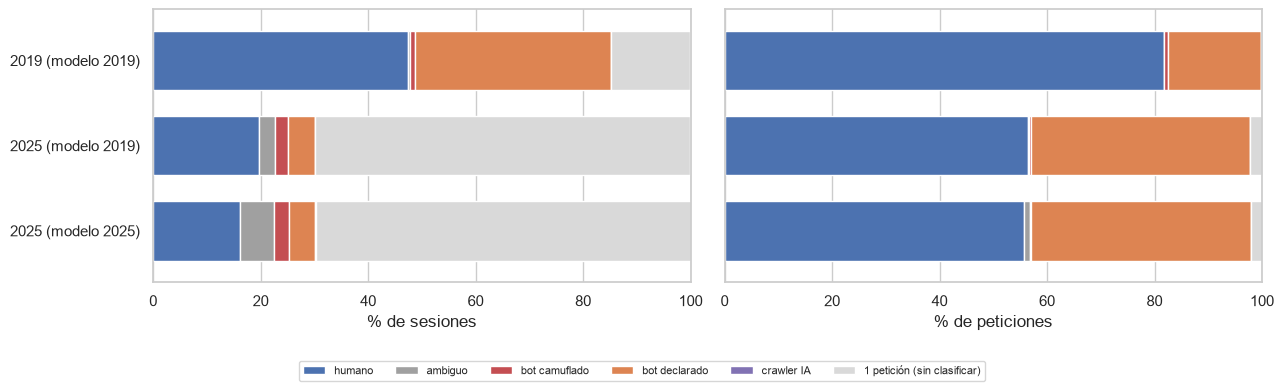

In [9]:
res19 = modelo19['resumen_2019']
comparacion = pd.concat({'2019 (modelo 2019)': res19['% sesiones'],
                         '2025 (modelo 2019)': res25_m19['% sesiones'],
                         '2025 (modelo 2025)': res25_m25['% sesiones']}, axis=1)
comparacion_pet = pd.concat({'2019 (modelo 2019)': res19['% peticiones'],
                             '2025 (modelo 2019)': res25_m19['% peticiones'],
                             '2025 (modelo 2025)': res25_m25['% peticiones']}, axis=1)
display(comparacion.rename(columns=lambda c: c + ' · % sesiones'))
display(comparacion_pet.rename(columns=lambda c: c + ' · % peticiones'))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for a, t, nom in [(ax[0], comparacion, '% de sesiones'), (ax[1], comparacion_pet, '% de peticiones')]:
    t.T.plot.barh(stacked=True, ax=a, color=[COLORES[c] for c in CATEGORIAS], legend=False, width=0.7)
    a.set(xlim=(0, 100), xlabel=nom)
ax[0].invert_yaxis()
fig.legend(CATEGORIAS, ncol=6, fontsize=8, loc='lower center', bbox_to_anchor=(0.5, -0.04))
plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.savefig('figuras/comparacion_2019_2025.png', dpi=150); plt.show()

In [10]:
# Crawlers de IA en 2025: comportamiento de sus sesiones
ia = ses25_m25[ses25_m25['tipo_ua'] == 'crawler_IA']
ia[['user_agent', 'n_peticiones', 'duracion_s', 'pct_estaticos', 'pct_sin_referer', 'grupo']].assign(
    user_agent=ia['user_agent'].str.extract(r'(GPTBot|Amazonbot|Bytespider|ClaudeBot|\w+Bot)', expand=False))

,user_agent,n_peticiones,duracion_s,pct_estaticos,pct_sin_referer,grupo
sesion,,,,,,
1589,Bytespider,1,0.0,0.0,1.0,—
6748,Amazonbot,1,0.0,0.0,1.0,—
6749,Amazonbot,1,0.0,0.0,1.0,—
6750,GPTBot,1,0.0,0.0,1.0,—
6751,GPTBot,1,0.0,0.0,0.0,—


**// Comentario:** Entre 2019 y 2025 el perfil del tráfico de ordenador cambia de forma notable: las sesiones de una sola petición pasan del 14,7 % al 69,7 %, los bots declarados del 17,3 % al 40,8 % de las peticiones y los bots camuflados del 0,9 % al 2,8 % de las sesiones. Parte de estas diferencias se deben al tipo de web, ya que se compara una tienda online con la web de un organismo público vigilada por servicios de monitorización y muy expuesta a escáneres. Respecto a los *crawlers* de IA, en 2019 solo aparece una sesión de CCBot (166 peticiones), y el log de 2025 contiene cinco sesiones (2 de GPTBot, 2 de Amazonbot y 1 de Bytespider), **todas de una única petición**, por lo que no es posible estudiar su comportamiento ni comprobar en qué clúster caerían; la herramienta las contabiliza correctamente gracias a su *user-agent*.

## 5. Conclusiones

- **El modelo de 2019 no generaliza directamente.** Aplicado al log de 2025, asigna a sus grupos sesiones que no encajan con su perfil (por ejemplo, el crawler lento recibe sesiones con 0,5 s entre peticiones), por lo que es necesario reentrenarlo con los datos de cada web.
- **Reentrenado con los datos de 2025**, la elección de k es clara (k = 9, mejor en silhouette y en Davies-Bouldin) y vuelven a aparecer grupos interpretables, entre ellos uno de errores 4xx que reúne escáneres de vulnerabilidades.
- **Validación independiente del *user-agent*.** Según las reglas de *ground truth*, ninguna de las 671 sesiones de navegación humana contiene un ataque, mientras que el 21,1 % de los bots camuflados sí lo hacen, frente al 0,6 % de las sesiones humanas.
- **El peso de los bots depende de cómo se mida:** en 2025 los bots declarados son el 5,0 % de las sesiones de ordenador pero el 40,8 % de las peticiones, por los servicios de monitorización.

**Limitaciones.** El 70 % de las sesiones de ordenador de 2025 son de una sola petición y concentran el 87 % de los ataques, que quedan fuera del clustering. Los *crawlers* de IA del log (2 de GPTBot, 2 de Amazonbot y 1 de Bytespider) hacen una única petición cada uno, por lo que no ha podido estudiarse su comportamiento.

## Referencias

- *Web Server Log Dataset* (2026). Zenodo, licencia MIT. https://doi.org/10.5281/zenodo.20001206
- Zaker, F. (2019). *Online Shopping Store – Web Server Logs*. Harvard Dataverse, V1. https://doi.org/10.7910/DVN/3QBYB5